# Quiescence Model

Ajuste por mínimos cuadrados para un modelo exponencial de la reduccion de viabilidad debido a la quiescenica extendida, usando datos experimentales de (Oliva et al. 2018, ref. [8]) obtenidos con mosquitos de Recife - Brasil.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
import os

In [ ]:
plt.rcParams.update({'font.size': 22})

## 1. Datos experimentales (Oliva et al. 2018, ref. [8]) — Recife

Se usan fracciones (0–1).

In [ ]:

# Días de sequía (quiescencia) en los que se midió la eclosión
dias = np.array([0, 10, 40, 70, 100, 130, 160], dtype=float)
# Porcentaje de huevos que eclosionó en cada tiempo, dividido por 100 para trabajar con fracciones (0 a 1).
# En el día 0 la viabilidad es 100 % (= 1) por definición.
viab = np.array([100, 43.1, 14.0, 10.9, 4.9, 0.8, 0.0]) / 100

## 2. Ajuste

IC al 95 %

In [ ]:
# Funcion exponencial
def eps_fn(x, beta):
    return np.exp(-beta * x)

beta = 0.0737 d^-1   SE = 0.0118   IC95% = [0.0448, 0.1025]
R2 = 0.971   RMSE = 0.057 (fraccion)   n = 7, gl = 6


In [ ]:
# Ajuste
popt, pcov = curve_fit(eps_fn, dias, viab, p0=[0.03], bounds=([0], [1]))
beta = popt[0]
se = np.sqrt(pcov[0, 0])

n, dof = len(dias), len(dias) - 1
tcrit = stats.t.ppf(0.975, dof)          # valor crítico t para 95 % bilateral
b_lo, b_hi = beta - tcrit*se, beta + tcrit*se


In [ ]:
# Medidas de calidad del ajuste
res = viab - eps_fn(dias, beta)          # residuos: observado - predicho
rss = float(res @ res)
tss = float(((viab - viab.mean())**2).sum())
r2 = 1 - rss/tss                         # R²
rmse = np.sqrt(rss/n)                    # error típico del modelo

print(f"beta = {beta:.4f} d^-1   SE = {se:.4f}   IC95% = [{b_lo:.4f}, {b_hi:.4f}]")
print(f"R2 = {r2:.3f}   RMSE = {rmse:.3f} (fraccion)   n = {n}, gl = {dof}")

### Tiempos hasta 50 % y 10 % de viabilidad

In [ ]:

# Se despeja tau en e^(-beta*tau) = p  ->  tau = -ln(p) / beta
def t_p(b, p):
    return -np.log(p) / b

# p = 0.5 -> tiempo en que la viabilidad se reduce a la mitad (t50)
# p = 0.1 -> tiempo en que queda solo el 10 % (t10)
for pr in (0.5, 0.1):
    print(f"t_{int(pr*100)}% = {t_p(beta, pr):5.1f} dias   IC95% = [{t_p(b_hi, pr):.1f}, {t_p(b_lo, pr):.1f}]")

t_50% =   9.4 dias   IC95% = [6.8, 15.5]
t_10% =  31.3 dias   IC95% = [22.5, 51.4]


## 3. Figura con banda de confianza

La banda es la envolvente de e^(−βτ) para β entre los extremos del IC95 %.

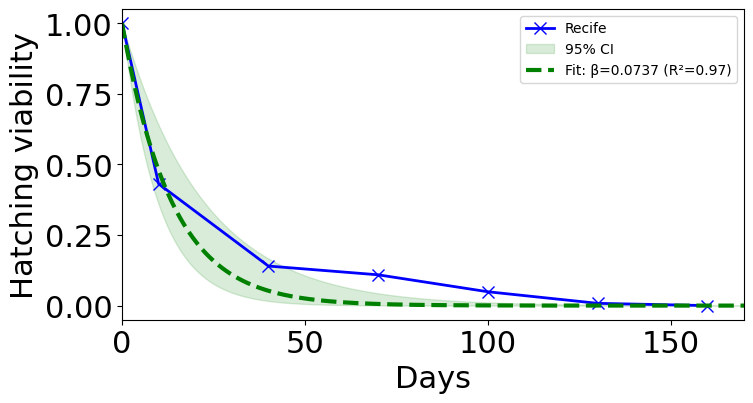

In [ ]:
t = np.linspace(0, 170, 300)
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(dias, viab, 'blue', lw=2, marker='x', ms=9, label='Recife')

# Banda sombreada: como e^(-beta*t) es monótona en beta, la curva con el beta menor del IC es el
# borde superior y la del beta mayor es el borde inferior
ax.fill_between(t, eps_fn(t, b_hi), eps_fn(t, b_lo), color='green', alpha=0.15, label='95% CI')

# Curva ajustada con el beta óptimo
ax.plot(t, eps_fn(t, beta), 'green', lw=3, ls='--', label=f'Fit: β={beta:.4f} (R²={r2:.2f})')

ax.set_xlabel('Days'); ax.set_ylabel('Hatching viability')
ax.set_xlim(0, 170)
ax.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()